Accuracy of XGBoost model: 1.00


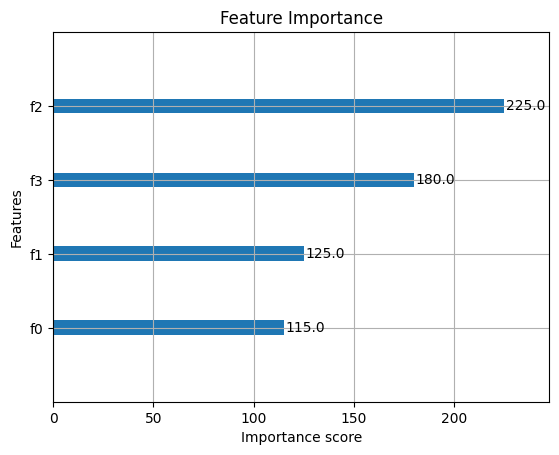

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

data = load_iris()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

params = {
    'objective': 'multi:softmax',
    'num_class': 3,
    'max_depth': 3,
    'learning_rate': 0.1,
    'n_estimators': 100,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'eval_metric': 'merror'
}

xgb_model = xgb.XGBClassifier(**params)
xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f'Accuracy of XGBoost model: {accuracy:.2f}')

xgb.plot_importance(xgb_model, importance_type='weight', max_num_features=4)
plt.title('Feature Importance')
plt.show()